# Conditional generation of e-commerce product descriptions (GPT-2, v2)

**Kaggle-ready, independent notebook.** Input: `amazon_balanced_dataset.csv` (~100,000 products) for training, for training and validation, plus a fixed 1,000-product test split. Goal: generate a product description *conditioned on structured product features*.

| Pipeline step | Deliverable | Where |
|---|---|---|
| 1. Dataset | ≥10,000 (features, description) pairs | §3 (~100,000-pair file → 30,000 training pairs; fixed 1,000-product test set) |
| 2. Preprocessing | structured → coherent text script | §4 (`product_prompt.py`: `parse_input_text`, `to_sentences`, `clean_text`) |
| 3. Representation | token embeddings + specific encoding of structured fields | §5–6 (field tokens `<\|title\|>`, `<\|features\|>`, `<\|details\|>`… with per-field token budgets) |
| 4. Modeling | conditional GPT-2 fine-tuning | §7–8 |
| 5. Evaluation | BLEU + perplexity + human evaluation | §9–13 |
| 6. Application | generation tool | separate application — see §15 for the exact interface to reuse |

**What changed compared with v1 (and why it should score better)**

1. **Field-aware encoding** (`ENCODING='tokens'`): each field gets its own marker token and its own token budget. v1 truncated the *end* of one long string, so `Details` (color, size…) was the first thing lost.
2. **Category in the prompt** (randomly dropped 10% of the time so the model also works without it).
3. **Better training targets:** HTML/URL cleaning, a wider length filter (more training rows), and truncation at a *sentence boundary* (v1 cut mid-sentence and then added EOS, teaching the model to stop abruptly).
4. **Better optimisation:** mixed precision (fp16), AdamW with weight decay, warm-up + linear decay, 2 epochs on up to 30,000 training pairs with early stopping, evaluated on a 1,000-row validation set (v1: 200 rows).
5. **Better decoding:** `no_repeat_ngram_size` in HF also looks at the *prompt*, so v1 could not copy 3-word phrases from the product facts. Here the n-gram block only applies to generated text, there is no repetition penalty on the prompt, and the decoding settings are chosen on validation data.
6. **Complete evaluation:** BLEU, chrF, perplexity on the test set, automatic faithfulness proxies (invented numbers, detail/title coverage), a zero-shot baseline, and a ready-to-fill human-evaluation sheet.

**Kaggle setup:** GPU on (T4), Internet on for the first model download, dataset attached with *Add Input*. Outputs are kept with *Save Version → Save & Run All*.

## 1 — Imports, configuration, GPU check

In [1]:
import os, gc, re, json, math, random, time, shutil, sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================ CONFIG ============================
ENCODING          = 'tokens'   # 'tokens' = field marker tokens (recommended) | 'text' = natural-language sentences
MODEL_NAME        = 'openai-community/gpt2'   # 'openai-community/gpt2-medium' may give better text (use BATCH_SIZE=2, ACCUM_STEPS=8)
BATCH_SIZE        = 8
ACCUM_STEPS       = 2          # effective batch = BATCH_SIZE * ACCUM_STEPS
EPOCHS            = 2          # big training set: 2 epochs is enough and fits the Kaggle session limit
MAX_TRAIN_ROWS    = 30000      # cap on training rows taken from the big file (raise to 40000 if time allows)
N_VAL             = 1000       # validation rows taken from the big file
LR                = 5e-5
WARMUP_RATIO      = 0.06
WEIGHT_DECAY      = 0.01
PATIENCE          = 1          # stop if validation loss does not improve for this many epochs
CATEGORY_DROPOUT  = 0.10       # prompts built without the category, so the app works without it too
MAX_PROMPT_TOKENS = 320
MAX_TARGET_TOKENS = 160
N_EVAL            = 200        # test products used for BLEU / faithfulness (first 100 = same sample as v1)
N_HUMAN           = 40         # rows exported for human evaluation
# ===========================================================================

OUT_DIR = Path('/kaggle/working') if Path('/kaggle').exists() else Path('./outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_DIR = OUT_DIR / f'gpt2-{ENCODING}-best'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, '| mixed precision:', AMP)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
assert DEVICE.type == 'cuda', 'Turn on GPU in Kaggle Notebook Settings.'

Device: cuda | mixed precision: True
GPU: Tesla T4


## 2 — Install libraries

In [2]:
%pip install -q transformers accelerate sacrebleu scikit-learn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 8.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## 3 — Dataset (deliverable 1)

The data comes from Amazon products:

- **`amazon_balanced_dataset.csv` (~100,000 rows)** → source of the *training* data (capped at `MAX_TRAIN_ROWS`) and of a small validation set.
- **A fixed 1,000-product test split**, rebuilt with the *same seed and stratified split as v1*, so BLEU stays comparable with v1 and the Qwen runs. Every test product is removed from the big file (exact match) so there is no leakage.

The data has `category`, `input_text` (`Title: … | Features: … | Details: …`) and `target_text`.

In [3]:
def find_csv(name, fallback=None):
    for root in ['/kaggle/input', '.']:
        if Path(root).exists():
            hits = sorted(Path(root).rglob(name)) or sorted(Path(root).rglob(name + '.gz'))
            if hits: return hits[0]
    if fallback and Path(fallback).exists(): return Path(fallback)
    raise AssertionError(f'Attach the dataset containing {name} as a Kaggle Input')

BIG_PATH   = find_csv('amazon_balanced_dataset.csv', '/kaggle/input/datasets/mohamedahouir/project/amazon_balanced_dataset.csv')
SMALL_PATH = find_csv('amazon_12k.csv', '/kaggle/input/datasets/mohamedahouir/project/amazon_12k.csv')

def load_clean(path):
    d = pd.read_csv(path)
    req = {'category', 'input_text', 'target_text'}
    assert req.issubset(d.columns), f'{path.name}: missing columns {req - set(d.columns)}'
    d = d.dropna(subset=list(req)).copy()
    d['input_text'] = d['input_text'].astype(str).str.strip()
    d['target_text'] = d['target_text'].astype(str).str.strip()
    return d[(d.input_text != '') & (d.target_text != '')].reset_index(drop=True)

big = load_clean(BIG_PATH)
small = load_clean(SMALL_PATH)
print('Big dataset  :', BIG_PATH, '|', len(big), 'rows')
print('Test source   :', SMALL_PATH, '|', len(small), 'rows')
print('\nBig dataset, rows per category:'); print(big.category.value_counts().to_string())
display(big[['category', 'input_text', 'target_text']].head(2))
df = big   # used by later cells for category names

Big dataset  : /kaggle/input/datasets/mohamedahouir/project/amazon_balanced_dataset.csv | 100000 rows
Test source   : /kaggle/input/datasets/mohamedahouir/project/amazon_12k.csv | 12000 rows

Big dataset, rows per category:
category
All_Beauty             10000
Video_Games            10000
Software               10000
Electronics            10000
Home_and_Kitchen       10000
Office_Products        10000
Sports_and_Outdoors    10000
Toys_and_Games         10000
Pet_Supplies           10000
Musical_Instruments    10000


,category,input_text,target_text
0,All_Beauty,generate product description: Title: Precision...,The Precision Plunger Bars are designed to wor...
1,All_Beauty,generate product description: Title: Lurrose 1...,Description The false toenails are durable wit...


## 4 — Preprocessing script: structured features → text (deliverable 2)

All preprocessing and prompt-building logic lives in **one module, `product_prompt.py`**, written to disk by the next cell. The notebook *and the application* import the same file, so training and inference can never drift apart.

- `parse_input_text` splits the serialised string into `title`, `features` (list) and `details` (list of `(name, value)` pairs).
- `to_sentences` turns them into coherent sentences, e.g. `Its color is Black.` (this is the `ENCODING='text'` format).
- `build_prompt_ids` builds the model input (§6) — field-marker tokens for `ENCODING='tokens'`.
- `clean_text` removes HTML, URLs and extra spaces from target descriptions.
- `generate_batch` / `describe` run generation (used for evaluation and by the app).

In [4]:
MODULE = r"""
import re, html

SPECIALS = ['<|category|>', '<|title|>', '<|features|>', '<|details|>', '<|desc|>']
BUDGET = {'category': 8, 'title': 56, 'features': 150, 'details': 64}   # max tokens per field
TEXT_PREFIX = 'Write an accurate e-commerce description using only the product facts below.\nProduct facts: '
TEXT_SUFFIX = '\nDescription:'
DEFAULT_GEN = {'max_new_tokens': 160, 'min_new_tokens': 40, 'num_beams': 4, 'early_stopping': True,
               'length_penalty': 1.2, 'ngram_block': 3}

_PREFIX = re.compile(r'^\s*generate product description\s*:\s*', re.I)
_SPLIT = re.compile(r'(?:^|\s\|\s)([A-Z][A-Za-z ]{1,24}):\s*')


def _items(v):
    return [s.strip(' .') for s in re.split(r';\s*', v) if s.strip(' .')]


def _details(v):
    out = []
    for it in _items(v):
        if ':' in it:
            k, val = it.split(':', 1)
            if k.strip() and val.strip():
                out.append((k.strip(), val.strip()))
                continue
        out.append(('', it))
    return out


def parse_input_text(text):
    # 'generate product description: Title: X | Features: a; b | Details: Color: Black'
    t = _PREFIX.sub('', str(text)).strip()
    parts = _SPLIT.split(t)
    d = {'title': '', 'features': [], 'details': []}
    pre = parts[0].strip()
    extras = []
    for k, v in zip(parts[1::2], parts[2::2]):
        k = k.strip().lower()
        v = v.strip()
        if k == 'title':
            d['title'] = v
        elif k == 'features':
            d['features'] = _items(v)
        elif k == 'details':
            d['details'] = _details(v)
        elif v:
            extras.append((k.title(), v))
    d['details'] = d['details'] + extras
    if not d['title']:
        d['title'] = pre
    if not d['title'] and not d['features'] and not d['details']:
        d['title'] = t
    return d


def make_record(title, features=None, details=None):
    # build a record from user input (used by the app); features: str or list, details: dict / str / list of pairs
    if isinstance(features, str):
        features = _items(features.replace('\n', ';'))
    if isinstance(details, dict):
        details = [(str(k), str(v)) for k, v in details.items() if str(v).strip()]
    elif isinstance(details, str):
        details = _details(details.replace('\n', ';'))
    return {'title': (title or '').strip(), 'features': list(features or []), 'details': list(details or [])}


def to_sentences(d, category=None):
    s = []
    if category:
        s.append('Category: ' + str(category).replace('_', ' ') + '.')
    if d['title']:
        s.append('The product is ' + d['title'].strip().rstrip('.') + '.')
    for k, v in d['details']:
        s.append(('Its ' + k.lower() + ' is ' + v.rstrip('.') + '.') if k else (v.rstrip('.') + '.'))
    if d['features']:
        s.append('Key features: ' + '; '.join(d['features']) + '.')
    return ' '.join(s)


def facts_text(d):
    return ' '.join([d['title']] + d['features'] + [(k + ' ' + v) for k, v in d['details']])


def clean_text(t):
    t = html.unescape(str(t))
    t = re.sub(r'<[^>]+>', ' ', t)
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()


def alpha_ratio(t):
    return sum(c.isalpha() for c in t) / max(1, len(t))


def _enc(tok, s):
    return tok.encode(s, add_special_tokens=False)


def build_prompt_ids(tok, d, category=None, mode='tokens', max_tokens=320):
    if mode == 'tokens':
        sp = {s: tok.convert_tokens_to_ids(s) for s in SPECIALS}
        ids = []
        if category:
            ids += [sp['<|category|>']] + _enc(tok, ' ' + str(category).replace('_', ' '))[:BUDGET['category']]
        if d['title']:
            ids += [sp['<|title|>']] + _enc(tok, ' ' + d['title'])[:BUDGET['title']]
        if d['features']:
            ids += [sp['<|features|>']] + _enc(tok, ' ' + ' ; '.join(d['features']))[:BUDGET['features']]
        if d['details']:
            det = ' ; '.join((k + ': ' + v) if k else v for k, v in d['details'])
            ids += [sp['<|details|>']] + _enc(tok, ' ' + det)[:BUDGET['details']]
        return ids[:max_tokens - 1] + [sp['<|desc|>']]
    head, tail = _enc(tok, TEXT_PREFIX), _enc(tok, TEXT_SUFFIX)
    body = _enc(tok, to_sentences(d, category))[:max_tokens - len(head) - len(tail)]
    return head + body + tail


def _ngram_processor(n, prompt_len):
    # blocks repeated n-grams in the GENERATED text only (HF's built-in version also blocks copying from the prompt)
    from transformers import LogitsProcessor

    class GenOnlyNoRepeat(LogitsProcessor):
        def __call__(self, input_ids, scores):
            gen = input_ids[:, prompt_len:].tolist()
            for b, seq in enumerate(gen):
                if len(seq) < n:
                    continue
                prefix = tuple(seq[len(seq) - n + 1:])
                banned = [seq[i + n - 1] for i in range(len(seq) - n + 1) if tuple(seq[i:i + n - 1]) == prefix]
                if banned:
                    scores[b, banned] = float('-inf')
            return scores
    return GenOnlyNoRepeat()


def generate_batch(model, tok, prompts, gen_cfg=None, device='cuda', batch_size=16, amp=True):
    import torch
    from transformers import LogitsProcessorList
    cfg = dict(gen_cfg or DEFAULT_GEN)
    ngram = cfg.pop('ngram_block', 0)
    pad = tok.eos_token_id
    use_amp = bool(amp) and str(device).startswith('cuda')
    model.eval()
    outs = []
    for i in range(0, len(prompts), batch_size):
        chunk = prompts[i:i + batch_size]
        L = max(len(p) for p in chunk)
        ids = torch.full((len(chunk), L), pad, dtype=torch.long)
        mask = torch.zeros((len(chunk), L), dtype=torch.long)
        for j, p in enumerate(chunk):
            ids[j, L - len(p):] = torch.tensor(p, dtype=torch.long)
            mask[j, L - len(p):] = 1
        procs = LogitsProcessorList([_ngram_processor(ngram, L)]) if ngram else None
        with torch.inference_mode(), torch.autocast(device_type=torch.device(device).type, dtype=torch.float16, enabled=use_amp):
            out = model.generate(input_ids=ids.to(device), attention_mask=mask.to(device), pad_token_id=pad,
                                 eos_token_id=tok.eos_token_id, logits_processor=procs, **cfg)
        for j in range(len(chunk)):
            outs.append(tok.decode(out[j, L:], skip_special_tokens=True).strip())
    return outs


def describe(model, tok, record, category=None, mode='tokens', gen_cfg=None, max_prompt_tokens=320, device='cuda'):
    ids = build_prompt_ids(tok, record, category, mode, max_prompt_tokens)
    return generate_batch(model, tok, [ids], gen_cfg, device)[0]
"""

(OUT_DIR / 'product_prompt.py').write_text(MODULE)
if str(OUT_DIR) not in sys.path:
    sys.path.insert(0, str(OUT_DIR))
import importlib, product_prompt as pp
importlib.reload(pp)

# ---- check the parser on real rows
for t in df.input_text.head(3):
    d = pp.parse_input_text(t)
    print('TITLE   :', d['title'][:100])
    print('FEATURES:', len(d['features']), '|', d['features'][:2])
    print('DETAILS :', d['details'][:4])
    print('SENTENCES:', pp.to_sentences(d, 'Pet_Supplies')[:250], '\n')

TITLE   : Precision Plunger Bars for Cartridge Grips – 93mm – Bag of 10 Plungers
FEATURES: 6 | ['Material: 304 Stainless Steel', 'Brass tip']
DETAILS : [('UPC', '644287689178')]
SENTENCES: Category: Pet Supplies. The product is Precision Plunger Bars for Cartridge Grips – 93mm – Bag of 10 Plungers. Its upc is 644287689178. Key features: Material: 304 Stainless Steel; Brass tip; Lengths Available: 88mm, 93mm, 98mm; Accepts cartridge nee 

TITLE   : Lurrose 100Pcs Full Cover Fake Toenails Artificial Transparent Nail Tips Nail Art for DIY
FEATURES: 5 | ['The false toenails are durable with perfect length. You have the option to wear them long or clip them short, easy to trim and file them to in any length and shape you like', 'ABS is kind of green enviromental material, and makes the nails durable, breathable, light even no pressure on your own nails']
DETAILS : [('Color', 'As Shown'), ('Size', 'Large'), ('Material', 'Acrylonitrile Butadiene Styrene (ABS)'), ('Brand', 'Lurrose')]
SENTENCE

### Split, leakage check and cleaning

- **Test set** = the same 1,000 products as in v1 (stratified split with `random_state=42`). Test references stay raw.
- **Training pool** = the big file *minus* every product that also appears in the test set, then cleaned (HTML/URLs, length, duplicates) and capped at `MAX_TRAIN_ROWS`, sampled evenly across categories.
- **Validation** = a separate 1,000-row sample from the big file (cleaned, disjoint from train and test).

In [5]:
from sklearn.model_selection import train_test_split

# ---- 1) test set: identical to the v1 split
if len(small) == 12000:
    _tr, _tmp = train_test_split(small, train_size=10000, random_state=SEED, stratify=small.category)
else:
    _tr, _tmp = train_test_split(small, train_size=0.8, random_state=SEED, stratify=small.category)
_val12, test_df = train_test_split(_tmp, test_size=0.5, random_state=SEED, stratify=_tmp.category)
test_df = test_df.reset_index(drop=True)

# ---- 2) remove test products from the big file (no leakage)
norm = lambda s: s.str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
test_inputs, test_targets = set(norm(test_df.input_text)), set(norm(test_df.target_text))
pool = big.copy()
leak = norm(pool.input_text).isin(test_inputs) | norm(pool.target_text).isin(test_targets)
print(f'Removed {int(leak.sum())} big-file rows that match a test product (exact match)')
pool = pool[~leak].copy()

# ---- 3) cleaning of the training pool
def words(s): return s.str.split().str.len()
pool['target_clean'] = pool.target_text.map(pp.clean_text)
n0 = len(pool)
pool = pool[words(pool.target_clean).between(20, 200)
            & (pool.target_clean.map(pp.alpha_ratio) >= 0.6)
            & (words(pool.input_text) >= 8)]
pool = pool.drop_duplicates(subset=['input_text', 'target_clean']).drop_duplicates(subset=['input_text']).reset_index(drop=True)
print(f'Cleaning: {n0} -> {len(pool)} usable rows in the big file')

# ---- 4) validation (1,000 rows) and capped training set, balanced across categories
n_cat = pool.category.nunique()
val_df = pd.concat([g.sample(n=min(len(g), N_VAL // n_cat), random_state=SEED) for _, g in pool.groupby('category')]).reset_index(drop=True)
rest = pool[~pool.input_text.isin(set(val_df.input_text))]
per_cat = MAX_TRAIN_ROWS // n_cat
train_df = pd.concat([g.sample(n=min(len(g), per_cat), random_state=SEED) for _, g in rest.groupby('category')])
train_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

test_df = test_df.copy()
for x in (train_df, val_df, test_df):
    x['parsed'] = x.input_text.map(pp.parse_input_text)

print(f'\nTrain: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}')
assert not (set(train_df.input_text) & set(test_df.input_text)), 'train/test overlap'
assert not (set(val_df.input_text) & set(test_df.input_text)), 'val/test overlap'
assert not (set(train_df.input_text) & set(val_df.input_text)), 'train/val overlap'
print('Overlap checks passed (train / validation / test are disjoint).')
print(train_df.category.value_counts().to_string())
st = pd.DataFrame({'has_title': train_df.parsed.map(lambda d: bool(d['title'])),
                   'has_features': train_df.parsed.map(lambda d: bool(d['features'])),
                   'has_details': train_df.parsed.map(lambda d: bool(d['details']))})
print('\nParsed fields (share of training rows):\n', st.mean().round(3).to_string())

Removed 1430 big-file rows that match a test product (exact match)
Cleaning: 98570 -> 71839 usable rows in the big file

Train: 30000 | Validation: 1000 | Test: 1000
Overlap checks passed (train / validation / test are disjoint).
category
All_Beauty             3000
Sports_and_Outdoors    3000
Toys_and_Games         3000
Home_and_Kitchen       3000
Electronics            3000
Musical_Instruments    3000
Software               3000
Pet_Supplies           3000
Office_Products        3000
Video_Games            3000

Parsed fields (share of training rows):
 has_title       1.0
has_features    1.0
has_details     1.0


## 5 — Tokenizer and model

With `ENCODING='tokens'`, five marker tokens are added to the GPT-2 vocabulary and the embedding matrix is resized (new embeddings are learned during fine-tuning). Token embeddings for the description come from GPT-2 itself; the marker tokens are the **specific encoding of the structured fields**.

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

def load_tokenizer_and_model():
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    tok.pad_token = tok.eos_token
    mdl = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
    if ENCODING == 'tokens':
        tok.add_special_tokens({'additional_special_tokens': pp.SPECIALS})
        mdl.resize_token_embeddings(len(tok), pad_to_multiple_of=8)
    mdl.config.pad_token_id = tok.pad_token_id
    return tok, mdl.to(DEVICE)

tokenizer, model = load_tokenizer_and_model()
print('Parameters:', format(sum(p.numel() for p in model.parameters()), ','))
print('Vocabulary:', len(tokenizer), '| embedding rows:', model.get_input_embeddings().weight.shape[0])
if ENCODING == 'tokens':
    print('Marker token ids:', {s: tokenizer.convert_tokens_to_ids(s) for s in pp.SPECIALS})

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Parameters: 124,445,184
Vocabulary: 50262 | embedding rows: 50264
Marker token ids: {'<|category|>': 50257, '<|title|>': 50258, '<|features|>': 50259, '<|details|>': 50260, '<|desc|>': 50261}


## 6 — Encode *prompt → description* (deliverable 3)

- **Prompt** = category + title + features + details, each behind its own marker token and truncated to its own budget (`pp.BUDGET`), so a long feature list can no longer push the details out.
- **Target** = the description, cut at a sentence boundary if it exceeds 160 tokens, followed by EOS. If no clean cut exists, no EOS is added (the model is not taught to stop mid-sentence).
- Only description tokens contribute to the loss (prompt labels = −100).

In [7]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

EOS = tokenizer.eos_token_id

def encode_target(text, max_tokens=MAX_TARGET_TOKENS):
    ids = tokenizer.encode(' ' + text, add_special_tokens=False)
    if len(ids) <= max_tokens:
        return ids + [EOS]
    cut = tokenizer.decode(ids[:max_tokens])
    k = max(cut.rfind('.'), cut.rfind('!'), cut.rfind('?'))
    if k >= 0.4 * len(cut):
        return tokenizer.encode(cut[:k + 1], add_special_tokens=False) + [EOS]
    return ids[:max_tokens]          # hard cut: no EOS

class ProductDataset(Dataset):
    def __init__(self, frame, target_col, cat_dropout=0.0, seed=SEED):
        rng = random.Random(seed)
        self.rows, self.n_truncated = [], 0
        for r in frame.itertuples(index=False):
            cat = None if rng.random() < cat_dropout else r.category
            p = pp.build_prompt_ids(tokenizer, r.parsed, cat, ENCODING, MAX_PROMPT_TOKENS)
            t = encode_target(getattr(r, target_col))
            if len(t) < 5:
                continue
            self.n_truncated += int(t[-1] != EOS)
            self.rows.append({'input_ids': torch.tensor(p + t, dtype=torch.long),
                              'labels': torch.tensor([-100] * len(p) + t, dtype=torch.long)})
    def __len__(self): return len(self.rows)
    def __getitem__(self, i): return self.rows[i]

def collate_fn(batch):
    ids = pad_sequence([b['input_ids'] for b in batch], batch_first=True, padding_value=tokenizer.pad_token_id)
    labels = pad_sequence([b['labels'] for b in batch], batch_first=True, padding_value=-100)
    mask = pad_sequence([torch.ones_like(b['input_ids']) for b in batch], batch_first=True, padding_value=0)
    return {'input_ids': ids, 'labels': labels, 'attention_mask': mask}

train_set = ProductDataset(train_df, 'target_clean', cat_dropout=CATEGORY_DROPOUT)
val_set   = ProductDataset(val_df, 'target_clean')
test_set  = ProductDataset(test_df, 'target_text')
print('Encoded train / val / test:', len(train_set), len(val_set), len(test_set))
print('Training targets without EOS (hard-cut):', train_set.n_truncated)

ex = train_set[0]
n_p = int((ex['labels'] == -100).sum())
print('\n--- PROMPT (masked) ---\n', tokenizer.decode(ex['input_ids'][:n_p]))
print('\n--- TARGET (learned) ---\n', tokenizer.decode(ex['input_ids'][n_p:]))
print('\nMean prompt tokens:', round(np.mean([int((r['labels'] == -100).sum()) for r in train_set.rows]), 1))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, pin_memory=True)
val_loader   = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, pin_memory=True)
test_loader  = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, pin_memory=True)
print('Micro-batches per epoch:', len(train_loader))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (2587 > 1024). Running this sequence through the model will result in indexing errors


Encoded train / val / test: 30000 1000 1000
Training targets without EOS (hard-cut): 235

--- PROMPT (masked) ---
 <|category|> All Beauty<|title|> Nars Kabuki Brush Set 8438<|features|> Nars Kabuki Brush Set 8438<|details|> Brand: NARS ; Skin Type: All ; Item Form: Wand ; Number of Pieces: 4 ; Age Range (Description): Adult ; Ferrule Material: Aluminum ; Skin Tone: All ; Item Dimensions LxWxH: 0.71 x 3.54 x 0.71 inches ; Item Weight: 1<|desc|>

--- TARGET (learned) ---
  Nars Kabuki Brush Set 8438 UPC: 607845084389 Mini Brush set featuring four Kabuki Brushes for eyes, cheeks and face. Set includes: - Hanamachi Kabuki Brush - Mini Ita Kabuki Brush - Kabuki Eye Brush - Kabuki Precision Eye Brush<|endoftext|>

Mean prompt tokens: 171.6
Micro-batches per epoch: 3750


## 7 — Fine-tuning (deliverable 4)

fp16 mixed precision, AdamW (no weight decay on biases / LayerNorm), 6% warm-up then linear decay, gradient clipping, gradient accumulation, early stopping on the **full** validation set. The best checkpoint (lowest validation loss) is saved together with the tokenizer.

In [8]:
from transformers import get_linear_schedule_with_warmup
from tqdm.auto import tqdm

@torch.no_grad()
def eval_loss(model, loader):
    model.eval()
    num = den = 0.0
    for batch in tqdm(loader, desc='Eval', leave=False):
        batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            loss = model(**batch).loss
        if not torch.isfinite(loss):
            raise RuntimeError('Non-finite evaluation loss')
        n = (batch['labels'][:, 1:] != -100).sum().item()
        num += loss.item() * n; den += n
    return num / max(1, den)

no_decay = ('bias', 'ln_')
groups = [
    {'params': [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], 'weight_decay': WEIGHT_DECAY},
    {'params': [p for n, p in model.named_parameters() if any(k in n for k in no_decay)], 'weight_decay': 0.0},
]
optimizer = torch.optim.AdamW(groups, lr=LR)
steps_per_epoch = math.ceil(len(train_loader) / ACCUM_STEPS)
total_steps = steps_per_epoch * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)

history, best_val, bad_epochs = [], float('inf'), 0
print(f'Optimizer steps per epoch: {steps_per_epoch} | total: {total_steps}')

for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    t0 = time.time(); loss_sum = tok_sum = 0.0
    bar = tqdm(train_loader, desc=f'Epoch {epoch}/{EPOCHS}')
    for i, batch in enumerate(bar, 1):
        batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            loss = model(**batch).loss
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite loss at epoch {epoch}, micro-batch {i}')
        group_start = ((i - 1) // ACCUM_STEPS) * ACCUM_STEPS
        group_size = min(ACCUM_STEPS, len(train_loader) - group_start)
        scaler.scale(loss / group_size).backward()
        if i % ACCUM_STEPS == 0 or i == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            optimizer.zero_grad(set_to_none=True)
        n = (batch['labels'][:, 1:] != -100).sum().item()
        loss_sum += loss.item() * n; tok_sum += n
        if i % 50 == 0:
            bar.set_postfix(train_loss=f'{loss_sum / max(1, tok_sum):.4f}')
    train_loss = loss_sum / max(1, tok_sum)
    val_loss = eval_loss(model, val_loader)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                    'val_perplexity': math.exp(val_loss), 'minutes': (time.time() - t0) / 60})
    print(f'Epoch {epoch}: train={train_loss:.4f} | val={val_loss:.4f} | val ppl={math.exp(val_loss):.2f} | {(time.time()-t0)/60:.1f} min')
    if val_loss < best_val - 1e-4:
        best_val, bad_epochs = val_loss, 0
        model.save_pretrained(SAVE_DIR); tokenizer.save_pretrained(SAVE_DIR)
        print('  -> saved new best model:', SAVE_DIR)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print('  -> early stopping'); break

hist_df = pd.DataFrame(history)
hist_df.to_csv(OUT_DIR / f'training_history_{ENCODING}.csv', index=False)
print('\nBest validation loss:', round(best_val, 4), '| perplexity:', round(math.exp(best_val), 2))
display(hist_df)

Optimizer steps per epoch: 1875 | total: 3750


Epoch 1/2:   0%|          | 0/3750 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
/tmp/ipykernel_23/391663138.py:49: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); scheduler.step()


Eval:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1: train=2.9739 | val=2.7664 | val ppl=15.90 | 20.6 min


...

Eval:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2: train=2.7567 | val=2.7342 | val ppl=15.40 | 20.7 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> saved new best model: /kaggle/working/gpt2-tokens-best

Best validation loss: 2.7342 | perplexity: 15.4


,epoch,train_loss,val_loss,val_perplexity,minutes
0,1,2.973869,2.766366,15.900745,20.620326
1,2,2.756717,2.734223,15.397772,20.679165


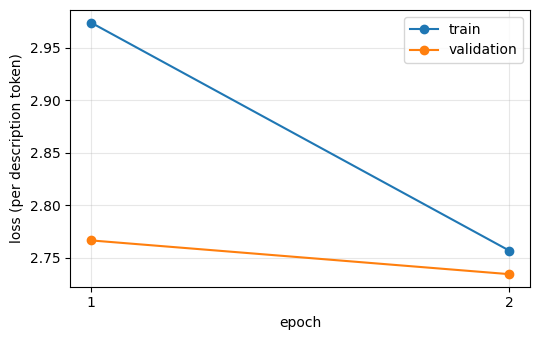

In [9]:
import matplotlib
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(hist_df.epoch, hist_df.train_loss, marker='o', label='train')
ax.plot(hist_df.epoch, hist_df.val_loss, marker='o', label='validation')
ax.set_xlabel('epoch'); ax.set_ylabel('loss (per description token)'); ax.legend(); ax.grid(alpha=.3)
ax.set_xticks(hist_df.epoch)
plt.tight_layout(); plt.savefig(OUT_DIR / 'learning_curve.png', dpi=150); plt.show()

## 8 — Reload the best checkpoint

In [10]:
del model, optimizer, scheduler, scaler
gc.collect(); torch.cuda.empty_cache()
tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(SAVE_DIR).to(DEVICE)
model.config.pad_token_id = tokenizer.pad_token_id
model.eval()
print('Loaded best model from', SAVE_DIR)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded best model from /kaggle/working/gpt2-tokens-best


## 9 — Metrics helpers

- **BLEU / chrF** (sacrebleu) against the Amazon reference — surface similarity.
- **Perplexity** on the test set — fluency (exp of the mean negative log-likelihood per description token).
- **Faithfulness proxies** (automatic, cheap, *not* a replacement for human evaluation):
  - `invented_number_rate` — share of outputs containing a number that does not appear in the product facts;
  - `detail_recall` — share of detail values (color, size, material…) that appear in the output;
  - `title_word_recall` — share of title words (≥4 letters) that appear in the output.

In [11]:
import sacrebleu
NUM = re.compile(r'\d+(?:[.,]\d+)?')

def fidelity_metrics(preds, parsed_list):
    inv, det, tit = [], [], []
    for pred, d in zip(preds, parsed_list):
        facts, p = pp.facts_text(d).lower(), pred.lower()
        inv.append(float(len(set(NUM.findall(p)) - set(NUM.findall(facts))) > 0))
        vals = [v.lower() for _, v in d['details'] if len(v) >= 2]
        if vals: det.append(np.mean([v in p for v in vals]))
        tw = set(re.findall(r'[a-z]{4,}', d['title'].lower()))
        if tw: tit.append(np.mean([w in p for w in tw]))
    return {'invented_number_rate': float(np.mean(inv)),
            'detail_recall': float(np.mean(det)) if det else float('nan'),
            'title_word_recall': float(np.mean(tit)) if tit else float('nan')}

def score(preds, refs, parsed_list):
    out = {'BLEU': sacrebleu.corpus_bleu(preds, [refs]).score,
           'chrF': sacrebleu.corpus_chrf(preds, [refs]).score,
           'mean_words_generated': float(np.mean([len(p.split()) for p in preds])),
           'mean_words_reference': float(np.mean([len(r.split()) for r in refs]))}
    out.update(fidelity_metrics(preds, parsed_list))
    return {k: round(v, 4) for k, v in out.items()}

def make_prompts(frame, tok=None, mode=None, use_category=True):
    tok = tok or tokenizer; mode = mode or ENCODING
    return [pp.build_prompt_ids(tok, d, (c if use_category else None), mode, MAX_PROMPT_TOKENS)
            for d, c in zip(frame.parsed, frame.category)]

## 10 — Choose decoding settings on validation data

Five decoding strategies are compared on 48 validation products (never on the test set). `ngram_block=3` forbids repeating a 3-gram *inside the generated text*. The best BLEU wins; check the output length too — very short outputs are penalised by BLEU's brevity penalty and look unhelpful.

In [12]:
GEN_CANDIDATES = {
    'v1_beam3 (110 tok, HF-style)': {'max_new_tokens': 110, 'num_beams': 3, 'early_stopping': True, 'ngram_block': 3},
    'beam4':          {'max_new_tokens': 160, 'min_new_tokens': 40, 'num_beams': 4, 'early_stopping': True, 'ngram_block': 3},
    'beam4_long':     {'max_new_tokens': 160, 'min_new_tokens': 60, 'num_beams': 4, 'early_stopping': True, 'length_penalty': 1.6, 'ngram_block': 3},
    'greedy':         {'max_new_tokens': 160, 'min_new_tokens': 40, 'ngram_block': 3},
    'sample_top_p':   {'max_new_tokens': 160, 'min_new_tokens': 40, 'do_sample': True, 'top_p': 0.9, 'temperature': 0.8, 'ngram_block': 3},
}
val_sub = val_df.sample(n=min(48, len(val_df)), random_state=1).reset_index(drop=True)
val_prompts = make_prompts(val_sub)
rows = []
for name, cfg in GEN_CANDIDATES.items():
    torch.manual_seed(SEED)
    t0 = time.time()
    preds = pp.generate_batch(model, tokenizer, val_prompts, cfg, DEVICE)
    s = score(preds, val_sub.target_clean.tolist(), list(val_sub.parsed))
    rows.append({'decoding': name, 'seconds': round(time.time() - t0), **{k: s[k] for k in ['BLEU', 'chrF', 'mean_words_generated', 'invented_number_rate', 'detail_recall']}})
    print(rows[-1])
gen_table = pd.DataFrame(rows).sort_values('BLEU', ascending=False).reset_index(drop=True)
display(gen_table)
BEST_NAME = gen_table.loc[0, 'decoding']
BEST_GEN = GEN_CANDIDATES[BEST_NAME]
print('Selected decoding:', BEST_NAME, BEST_GEN)

{'decoding': 'v1_beam3 (110 tok, HF-style)', 'seconds': 11, 'BLEU': 10.5635, 'chrF': 28.8409, 'mean_words_generated': 48.9375, 'invented_number_rate': 0.0417, 'detail_recall': 0.1788}
{'decoding': 'beam4', 'seconds': 20, 'BLEU': 14.0771, 'chrF': 32.7509, 'mean_words_generated': 57.2708, 'invented_number_rate': 0.1042, 'detail_recall': 0.1781}
{'decoding': 'beam4_long', 'seconds': 20, 'BLEU': 15.5413, 'chrF': 34.9619, 'mean_words_generated': 65.75, 'invented_number_rate': 0.1458, 'detail_recall': 0.1861}
{'decoding': 'greedy', 'seconds': 7, 'BLEU': 13.1205, 'chrF': 32.0821, 'mean_words_generated': 63.9583, 'invented_number_rate': 0.1042, 'detail_recall': 0.187}
{'decoding': 'sample_top_p', 'seconds': 7, 'BLEU': 11.3078, 'chrF': 30.9212, 'mean_words_generated': 67.5208, 'invented_number_rate': 0.1875, 'detail_recall': 0.1723}


,decoding,seconds,BLEU,chrF,mean_words_generated,invented_number_rate,detail_recall
0,beam4_long,20,15.5413,34.9619,65.7500,0.1458,0.1861
1,beam4,20,14.0771,32.7509,57.2708,0.1042,0.1781
2,greedy,7,13.1205,32.0821,63.9583,0.1042,0.1870
3,sample_top_p,7,11.3078,30.9212,67.5208,0.1875,0.1723
4,"v1_beam3 (110 tok, HF-style)",11,10.5635,28.8409,48.9375,0.0417,0.1788


Selected decoding: beam4_long {'max_new_tokens': 160, 'min_new_tokens': 60, 'num_beams': 4, 'early_stopping': True, 'length_penalty': 1.6, 'ngram_block': 3}


## 11 — Test-set evaluation (deliverable 5, automatic part)

- Perplexity on the **full test set** (1,000 products).
- BLEU / chrF / faithfulness proxies on `N_EVAL` test products. The first 100 are the *same sample as v1* (`random_state=2026`), so the 100-sample BLEU is directly comparable; the rest are extra products for a more stable estimate.

In [13]:
test_loss = eval_loss(model, test_loader)
TEST_PPL = math.exp(test_loss)
print(f'Test loss: {test_loss:.4f} | Test perplexity: {TEST_PPL:.2f}  (description tokens, up to {MAX_TARGET_TOKENS} per product)')

cmp_idx = test_df.sample(n=min(100, len(test_df)), random_state=2026).index
extra_n = max(0, min(N_EVAL, len(test_df)) - len(cmp_idx))
extra_idx = test_df.drop(cmp_idx).sample(n=extra_n, random_state=7).index if extra_n else []
eval_df = pd.concat([test_df.loc[cmp_idx], test_df.loc[extra_idx]]).reset_index(drop=True)

t0 = time.time()
torch.manual_seed(SEED)
eval_df['generated'] = pp.generate_batch(model, tokenizer, make_prompts(eval_df), BEST_GEN, DEVICE)
print(f'Generated {len(eval_df)} descriptions in {(time.time()-t0)/60:.1f} min')

refs = eval_df.target_text.tolist()
n_cmp = len(cmp_idx)
res_cmp = score(eval_df.generated[:n_cmp].tolist(), refs[:n_cmp], list(eval_df.parsed[:n_cmp]))
res_all = score(eval_df.generated.tolist(), refs, list(eval_df.parsed))
print(f'\nFirst {n_cmp} (same sample as v1):', res_cmp)
print(f'All {len(eval_df)}:', res_all)

eval_df.drop(columns=['parsed']).to_csv(OUT_DIR / 'test_outputs_v2.csv', index=False)
for i in range(3):
    print('\n' + '=' * 70)
    print('CATEGORY :', eval_df.category[i])
    print('FACTS    :', pp.to_sentences(eval_df.parsed[i])[:350])
    print('GENERATED:', eval_df.generated[i])
    print('REFERENCE:', eval_df.target_text[i][:350])

Eval:   0%|          | 0/125 [00:00<?, ?it/s]

Test loss: 2.7524 | Test perplexity: 15.68  (description tokens, up to 160 per product)
Generated 200 descriptions in 1.4 min

First 100 (same sample as v1): {'BLEU': 7.0168, 'chrF': 24.4531, 'mean_words_generated': 66.94, 'mean_words_reference': 128.35, 'invented_number_rate': 0.08, 'detail_recall': 0.1856, 'title_word_recall': 0.8184}
All 200: {'BLEU': 9.1007, 'chrF': 26.2522, 'mean_words_generated': 68.805, 'mean_words_reference': 120.575, 'invented_number_rate': 0.115, 'detail_recall': 0.2035, 'title_word_recall': 0.8231}

CATEGORY : All_Beauty
FACTS    : The product is FINGER LOVE Handmade Carved Wood Hair Stick Fairy Fox Ebony [Gift Box Set] (B Ebony). Its is discontinued by manufacturer is No. Its package dimensions is 9 x 1.9 x 0.3 inches. 0.35 Ounces. Its item model number is MZFZDOUBLEFOX01-1-F. Its manufacturer is FINGER LOVE. Key features: Total length: 7"; head part: 2" by 1". Diameter of s
GENERATED: Total length: 7" head part: 2" by 1". Diameter of stick: 8mm at its thic

## 12 — Baseline: pretrained GPT-2 without fine-tuning

Same products, same decoding, plain-text prompt (the pretrained model does not know the marker tokens). This shows what fine-tuning adds.

In [14]:
base_tok = AutoTokenizer.from_pretrained(MODEL_NAME); base_tok.pad_token = base_tok.eos_token
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(DEVICE).eval()
sub = eval_df.iloc[:n_cmp]
torch.manual_seed(SEED)
base_preds = pp.generate_batch(base_model, base_tok, make_prompts(sub, base_tok, 'text'), BEST_GEN, DEVICE)
res_base = score(base_preds, sub.target_text.tolist(), list(sub.parsed))
print('Zero-shot GPT-2:', res_base)
print('\nExample zero-shot output:', base_preds[0][:300])
del base_model; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Zero-shot GPT-2: {'BLEU': 6.3974, 'chrF': 23.9854, 'mean_words_generated': 104.19, 'mean_words_reference': 128.35, 'invented_number_rate': 0.39, 'detail_recall': 0.7319, 'title_word_recall': 0.902}

Example zero-shot output: Product: FINGER LOVE Handmade Carved Wood Hair Stick Fairy Fox Ebony [Gift Box Set] (B Ebony). Its is discontinued by manufacturer is No. Its package dimensions is 9 x 1.9 x 0.3 inches. 0.35 Ounces. Its item model number is MZFZDOUBLEFOX01-1-F. Its manufacturer is FINGer LOVE. Key features: Total le


## 13 — Results table and saved artifacts

In [15]:
comparison = pd.DataFrame([
    {'system': 'GPT-2 v1 notebook (reported)',            'BLEU (100)': 0.4052, 'val loss': 2.7837, 'perplexity': round(math.exp(2.7837), 2)},
    {'system': 'Qwen pretrained (reported, not strictly paired)', 'BLEU (100)': 3.42, 'val loss': None, 'perplexity': None},
    {'system': 'Qwen + LoRA (reported, not strictly paired)',     'BLEU (100)': 4.36, 'val loss': None, 'perplexity': None},
    {'system': 'GPT-2 zero-shot (this run)',                'BLEU (100)': res_base['BLEU'], 'val loss': None, 'perplexity': None},
    {'system': f'GPT-2 v2 fine-tuned [{ENCODING}] (this run)', 'BLEU (100)': res_cmp['BLEU'], 'val loss': round(best_val, 4), 'perplexity': round(TEST_PPL, 2)},
])
display(comparison)

RUN_CFG = {'encoding': ENCODING, 'model_name': MODEL_NAME, 'max_prompt_tokens': MAX_PROMPT_TOKENS,
           'max_target_tokens': MAX_TARGET_TOKENS, 'categories': sorted(df.category.unique().tolist()),
           'gen_cfg': BEST_GEN, 'gen_name': BEST_NAME}
RESULTS = {'config': RUN_CFG, 'best_val_loss': best_val, 'val_perplexity': math.exp(best_val),
           'test_loss': test_loss, 'test_perplexity': TEST_PPL,
           f'automatic_first_{n_cmp}': res_cmp, f'automatic_all_{len(eval_df)}': res_all, 'zero_shot_baseline': res_base,
           'decoding_search_validation': gen_table.to_dict('records')}
(OUT_DIR / 'results_v2.json').write_text(json.dumps(RESULTS, indent=2, default=str))
(SAVE_DIR / 'run_config.json').write_text(json.dumps(RUN_CFG, indent=2))
shutil.copy(OUT_DIR / 'product_prompt.py', SAVE_DIR / 'product_prompt.py')
print('Saved: results_v2.json, run_config.json and product_prompt.py (inside', SAVE_DIR.name + '/ for the application)')

,system,BLEU (100),val loss,perplexity
0,GPT-2 v1 notebook (reported),0.4052,2.7837,16.18
1,"Qwen pretrained (reported, not strictly paired)",3.4200,NaN,NaN
2,"Qwen + LoRA (reported, not strictly paired)",4.3600,NaN,NaN
3,GPT-2 zero-shot (this run),6.3974,NaN,NaN
4,GPT-2 v2 fine-tuned [tokens] (this run),7.0168,2.7342,15.68


Saved: results_v2.json, run_config.json and product_prompt.py (inside gpt2-tokens-best/ for your app)


## 14 — Human evaluation (deliverable 5, human part)

The next cell exports **`human_eval_sheet.csv`** with 40 products (4 per category). The sheet is meant for 2–3 raters (a `rater` column can be added). Scale 1–5 (5 = best):

| Column | Question |
|---|---|
| `relevance_1_5` | Does the text describe *this* product and read like a useful marketing description? |
| `fluency_1_5` | Is it grammatical and natural? |
| `faithfulness_1_5` | Does it use the given features correctly and avoid contradicting them? |
| `marketing_1_5` | Is it persuasive and well-structured for a product page? |
| `invented_facts_0_1` | **1 = the text states a specification / claim that is NOT in the input** (hallucination), 0 = none. |

The filled sheet is saved as `human_eval_filled.csv` (in `/kaggle/working` or as a Kaggle input) and processed by the aggregation cell.

In [16]:
parts = [g.sample(n=min(len(g), max(1, N_HUMAN // 10)), random_state=SEED) for _, g in eval_df.groupby('category')]
human = pd.concat(parts).reset_index(drop=True)
sheet = pd.DataFrame({
    'sample_id': range(1, len(human) + 1),
    'category': human.category,
    'product_facts': [pp.to_sentences(d)[:600] for d in human.parsed],
    'generated_description': human.generated,
    'reference_description': human.target_text.str[:600],
    'rater': '', 'relevance_1_5': '', 'fluency_1_5': '', 'faithfulness_1_5': '', 'marketing_1_5': '',
    'invented_facts_0_1': '', 'notes': ''})
sheet.to_csv(OUT_DIR / 'human_eval_sheet.csv', index=False)
print('Saved', OUT_DIR / 'human_eval_sheet.csv', '| rows:', len(sheet))

Saved /kaggle/working/human_eval_sheet.csv | rows: 40


In [17]:
cands = [OUT_DIR / 'human_eval_filled.csv']
if Path('/kaggle/input').exists():
    cands += sorted(Path('/kaggle/input').rglob('human_eval_filled.csv'))
filled = next((p for p in cands if p.exists()), None)
if filled is None:
    print('No human_eval_filled.csv found yet - fill human_eval_sheet.csv, save it under that name, then re-run this cell.')
else:
    he = pd.read_csv(filled)
    cols = ['relevance_1_5', 'fluency_1_5', 'faithfulness_1_5', 'marketing_1_5', 'invented_facts_0_1']
    for c in cols: he[c] = pd.to_numeric(he[c], errors='coerce')
    he = he.dropna(subset=cols, how='all')
    summary = he[cols].agg(['mean', 'std', 'count']).round(2).T
    display(summary)
    print(f"Hallucination rate (invented facts): {he['invented_facts_0_1'].mean():.1%} of {he['invented_facts_0_1'].count()} rated texts")
    display(he.groupby('category')[cols].mean().round(2))
    if 'rater' in he.columns and he['rater'].nunique() > 1:
        print('Ratings per rater:'); display(he.groupby('rater')[cols].mean().round(2))
    summary.to_csv(OUT_DIR / 'human_eval_summary.csv')

No human_eval_filled.csv found yet - fill human_eval_sheet.csv, save it under that name, then re-run this cell.


## 15 — Demo and how a separate application should call the model

The application must use **the same prompt as training**. These files are copied from the notebook output to the application folder: `gpt2-tokens-best/` (model + tokenizer + `run_config.json` + `product_prompt.py`). Usage:

```python
import json, torch
from transformers import AutoTokenizer, AutoModelForCausalLM
import product_prompt as pp                        # same file as the notebook

cfg = json.load(open('gpt2-tokens-best/run_config.json'))
tok = AutoTokenizer.from_pretrained('gpt2-tokens-best'); tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained('gpt2-tokens-best').eval()          # .to('cuda') if available
rec = pp.make_record(title, features='f1; f2', details={'Color': 'Black', 'Size': 'M'})
text = pp.describe(model, tok, rec, category, cfg['encoding'], cfg['gen_cfg'], cfg['max_prompt_tokens'], device='cpu')
```

`category` is optional (`None` works). Use the category names in `run_config.json['categories']` for a dropdown.

In [18]:
demos = [
    ('Wireless Bluetooth Headphones', 'Bluetooth 5.3; 30-hour battery life; foldable design', {'Color': 'Black'}, 'Electronics'),
    ('Stainless Steel Insulated Water Bottle 750ml', 'Keeps drinks cold 24 hours; leak-proof lid; BPA free', {'Color': 'Blue', 'Material': 'Stainless steel'}, 'Sports_and_Outdoors'),
    ('Organic Lavender Face Cream', 'Hydrating; for sensitive skin; no parabens', {'Size': '50 ml'}, 'All_Beauty'),
]
for title, feats, dets, cat in demos:
    rec = pp.make_record(title, feats, dets)
    print('\n' + '=' * 70)
    print('INPUT :', title, '|', feats, '|', dets, '|', cat)
    print('OUTPUT:', pp.describe(model, tokenizer, rec, cat, ENCODING, BEST_GEN, MAX_PROMPT_TOKENS, DEVICE))
print('\nWithout category:', pp.describe(model, tokenizer, pp.make_record(*demos[0][:3]), None, ENCODING, BEST_GEN, MAX_PROMPT_TOKENS, DEVICE))


INPUT : Wireless Bluetooth Headphones | Bluetooth 5.3; 30-hour battery life; foldable design | {'Color': 'Black'} | Electronics
OUTPUT: Bluetooth 5.3 Wireless Bluetooth Headphones are a great way to connect with friends, family, and colleagues. They are also great for connecting with other Bluetooth devices, such as cell phones, tablets, and more. The Bluetooth Headphone is designed to work with all Bluetooth devices. It can also be used as a Bluetooth headset. The wireless Bluetooth headset can be used with any Bluetooth device, including cell phones.

INPUT : Stainless Steel Insulated Water Bottle 750ml | Keeps drinks cold 24 hours; leak-proof lid; BPA free | {'Color': 'Blue', 'Material': 'Stainless steel'} | Sports_and_Outdoors
OUTPUT: Keeps drinks cold 24 hours. leak-proof lid. BPA free. Stainless Steel Insulated Water Bottle 750ml Stainless steel Insulated water bottle 750ml BPA Free Stainless steel insulated Water bottle 750 ml BPA FREE Stainless steel insulated water bottle 7.5

## 16 — Where to go next (if results are still low)

- **Ablation for the report:** set `ENCODING = 'text'`, re-run, and compare BLEU / perplexity / faithfulness with `'tokens'`.
- **Bigger model:** `MODEL_NAME = 'openai-community/gpt2-medium'`, `BATCH_SIZE = 2`, `ACCUM_STEPS = 8`.
- **BLEU stays low by nature:** Amazon descriptions are noisy marketing text, so two valid descriptions share few n-grams. Report BLEU **together with** perplexity, the faithfulness proxies and the human evaluation.
- Training descriptions come from sellers and may contain unsupported claims; always review generated text before using it publicly.